# Tugas Praktikum JS11 - Klasifikasi dengan Support Vector Machine

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

# Tugas 1 - SVM pada `voice.csv` (Kernel Linear, Polynomial, RBF)

## 1.1 Memuat dan Memeriksa Data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('voice.csv')
print('Ukuran data  :', df.shape)
print('Nilai kosong :', df.isna().sum().sum())
print()
print(df['label'].value_counts())
df.head()

Ukuran data  : (3168, 21)
Nilai kosong : 0

label
male      1584
female    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,0.000000,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,0.000000,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,0.000000,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,0.083878,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,0.104261,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Dataset `voice.csv` memiliki 3.168 baris data dan 21 kolom fitur akustik suara manusia yang diekstraksi dari rekaman audio. Seluruh nilai kolom bersifat numerik kontinu tanpa satu pun nilai kosong (`0 missing values`), dengan kolom target `label` yang terbagi secara seimbang sempurna antara kategori `male` (1.584 data) dan `female` (1.584 data). Keseimbangan proporsi 50%:50% ini sangat menguntungkan karena model klasifikasi tidak akan memiliki bias bawaan terhadap salah satu kelas mayoritas.

In [2]:
# rentang nilai tiap fitur akustik
df.drop(columns='label').describe().T[['min', 'max', 'mean', 'std']]

,min,max,mean,std
meanfreq,0.039363,0.251124,0.180907,0.029918
sd,0.018363,0.115273,0.057126,0.016652
median,0.010975,0.261224,0.185621,0.036360
Q25,0.000229,0.247347,0.140456,0.048680
Q75,0.042946,0.273469,0.224765,0.023639
IQR,0.014558,0.252225,0.084309,0.042783
skew,0.141735,34.725453,3.140168,4.240529
kurt,2.068455,1309.612887,36.568461,134.928661
sp.ent,0.738651,0.981997,0.895127,0.044980
sfm,0.036876,0.842936,0.408216,0.177521


Tabel deskriptif di atas memperlihatkan disparitas rentang nilai yang sangat tajam antar fitur akustik suara:
1. Sebagian besar fitur frekuensi seperti `meanfreq`, `sd`, `median`, `Q25`, dan `centroid` memiliki nilai fraksional yang sangat kecil pada kisaran `0,00` hingga `0,28` (skala $10^{-1}$).
2. Di sisi lain, fitur bentuk distribusi spektral seperti `kurt` (kurtosis) memiliki nilai maksimum mencapai `1.309,61` dengan standar deviasi `134,93`, serta `skew` mencapai `34,73`.
3. Fitur rentang frekuensi dominan (`maxdom` dan `dfrange`) memiliki rentang hingga `21,87`.

Perbedaan skala mencapai 4 orde magnitudo ($10^{-1}$ vs $10^{3}$) ini merupakan ancaman kritis bagi algoritma SVM. Karena SVM mengukur jarak geometris antar titik data (baik melalui perkalian skalar kernel linier maupun perhitungan jarak Euclidean kuadrat pada kernel RBF $\|x - x'\|^2$), fitur berorde ribuan seperti `kurt` akan mendominasi fungsi objektif secara mutlak dan menenggelamkan kontribusi fitur frekuensi fundamental lainnya. Oleh karena itu, standardisasi fitur dengan `StandardScaler` (mengubah setiap fitur menjadi rata-rata 0 dan variansi 1) bersifat wajib agar setiap dimensi diperlakukan secara setara.

## 1.2 Persiapan Data dan Split 70:30 serta 80:20

Label `male` diubah menjadi `1` dan `female` menjadi `0`. Split dilakukan secara stratified dengan
`random_state=42` supaya proporsi laki-laki dan perempuan tetap seimbang pada data latih maupun data uji.
Standardisasi (`StandardScaler`) dimasukkan ke dalam `Pipeline` sehingga rata-rata dan simpangan bakunya
hanya dihitung dari data latih, lalu dipakai pada data uji.

In [3]:
X = df.drop(columns='label').values
y = (df['label'] == 'male').astype(int).values

splits = {'70:30': 0.30, '80:20': 0.20}
data_split = {}
for nama, ukuran_uji in splits.items():
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=ukuran_uji, random_state=42, stratify=y
    )
    data_split[nama] = (Xtr, Xte, ytr, yte)
    print(f'Split {nama}: latih = {len(ytr)}, uji = {len(yte)}')

Split 70:30: latih = 2217, uji = 951
Split 80:20: latih = 2534, uji = 634


## 1.3 Pelatihan Model SVM (Linear, Polynomial, RBF)

In [4]:
kernels = {
    'Linear':     SVC(kernel='linear'),
    'Polynomial': SVC(kernel='poly'),     # degree=3 (bawaan)
    'RBF':        SVC(kernel='rbf'),
}

baris = []
model_terlatih = {}
for nama_split, (Xtr, Xte, ytr, yte) in data_split.items():
    for nama_kernel, svc in kernels.items():
        model = make_pipeline(StandardScaler(), svc)
        model.fit(Xtr, ytr)
        model_terlatih[(nama_split, nama_kernel)] = model
        baris.append({
            'Split': nama_split,
            'Kernel': nama_kernel,
            'Akurasi Latih': accuracy_score(ytr, model.predict(Xtr)),
            'Akurasi Uji': accuracy_score(yte, model.predict(Xte)),
            'Jumlah SV': model[-1].n_support_.sum(),
        })

hasil = pd.DataFrame(baris)
hasil

,Split,Kernel,Akurasi Latih,Akurasi Uji,Jumlah SV
0,70:30,Linear,0.972034,0.978970,201
1,70:30,Polynomial,0.966622,0.960042,611
2,70:30,RBF,0.983762,0.983176,326
3,80:20,Linear,0.976717,0.974763,215
4,80:20,Polynomial,0.968035,0.955836,665
5,80:20,RBF,0.983820,0.982650,349


### Tabulasi Akurasi Data Uji per Split dan Kernel

In [5]:
tabel_uji = hasil.pivot(index='Kernel', columns='Split', values='Akurasi Uji')
tabel_uji = tabel_uji.loc[['Linear', 'Polynomial', 'RBF'], ['70:30', '80:20']]
tabel_uji.round(4)

Split,70:30,80:20
Kernel,,
Linear,0.9790,0.9748
Polynomial,0.9600,0.9558
RBF,0.9832,0.9826


In [6]:
tabel_latih = hasil.pivot(index='Kernel', columns='Split', values='Akurasi Latih')
tabel_latih = tabel_latih.loc[['Linear', 'Polynomial', 'RBF'], ['70:30', '80:20']]
tabel_latih.round(4)

Split,70:30,80:20
Kernel,,
Linear,0.9720,0.9767
Polynomial,0.9666,0.9680
RBF,0.9838,0.9838


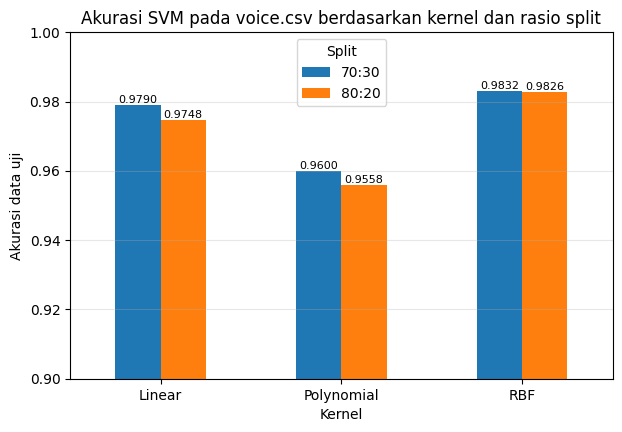

In [7]:
ax = tabel_uji.plot(kind='bar', figsize=(7, 4.5), rot=0)
ax.set_ylim(0.9, 1.0)
ax.set_ylabel('Akurasi data uji')
ax.set_title('Akurasi SVM pada voice.csv berdasarkan kernel dan rasio split')
for c in ax.containers:
    ax.bar_label(c, fmt='%.4f', fontsize=8)
ax.grid(True, axis='y', alpha=0.3)
plt.show()

Berdasarkan tabulasi performa pengujian di atas, ketiga jenis kernel SVM berhasil mencapai akurasi klasifikasi yang sangat tinggi (di atas 95%) pada kedua rasio split:

1. **Kernel RBF (Radial Basis Function)** mencatatkan akurasi pengujian tertinggi di kedua skenario:
   - Pada split **70:30**, RBF mencapai akurasi uji **0,9832** (98,32%) dengan akurasi latih **0,9838**.
   - Pada split **80:20**, RBF mencapai akurasi uji **0,9826** (98,26%) dengan akurasi latih **0,9838**.
   - Model RBF memerlukan sekitar 326 hingga 349 support vectors (hanya ~14% dari total data latih), mencerminkan batasan keputusan non-linear yang sangat fleksibel namun tetap teratur.

2. **Kernel Linear** menempati peringkat kedua dengan kinerja yang sangat kompetitif:
   - Pada split **70:30**, Linear mencapai akurasi uji **0,9790** (97,90%) dengan akurasi latih **0,9720**.
   - Pada split **80:20**, Linear mencapai akurasi uji **0,9748** (97,48%) dengan akurasi latih **0,9767**.
   - Kernel Linear memiliki jumlah support vector paling sedikit, yaitu 201 hingga 215 titik. Hal ini membuktikan bahwa sebagian besar fitur akustik suara pria dan wanita (terutama frekuensi fundamental `meanfun`) telah memiliki separabilitas linier yang sangat kuat setelah distandarisasi.

3. **Kernel Polynomial (degree=3)** mencatatkan akurasi terendah di antara ketiganya:
   - Pada split **70:30**, Polynomial meraih akurasi uji **0,9600** (96,00%).
   - Pada split **80:20**, Polynomial meraih akurasi uji **0,9558** (95,58%).
   - Model Polynomial membutuhkan jumlah support vectors terbanyak (611 hingga 665 titik, hampir dua kali lipat RBF), menandakan bahwa batas keputusan polinomial orde 3 cenderung lebih kompleks dan sedikit mengalami osilasi pada area perbatasan kelas.

## 1.4 Pengecekan Kestabilan dengan 20 Kali Split Acak

Hasil di atas berasal dari satu pembagian data (`random_state=42`). Untuk mengetahui apakah selisih antar
kernel dan antar rasio split konsisten, percobaan diulang dengan 20 nilai `random_state` yang berbeda.

In [8]:
baris = []
for seed in range(20):
    for nama_split, ukuran_uji in splits.items():
        Xtr, Xte, ytr, yte = train_test_split(
            X, y, test_size=ukuran_uji, random_state=seed, stratify=y
        )
        for nama_kernel, svc in kernels.items():
            m = make_pipeline(StandardScaler(), SVC(kernel=svc.kernel)).fit(Xtr, ytr)
            baris.append({'Split': nama_split, 'Kernel': nama_kernel,
                          'Akurasi Uji': m.score(Xte, yte)})

ulang = pd.DataFrame(baris)
ringkas = ulang.groupby(['Kernel', 'Split'])['Akurasi Uji'].agg(['mean', 'std', 'min', 'max'])
ringkas.round(4)

mean     std     min     max
Kernel     Split                                
Linear     70:30  0.9729  0.0043  0.9642  0.9800
           80:20  0.9737  0.0045  0.9621  0.9811
Polynomial 70:30  0.9556  0.0067  0.9401  0.9653
           80:20  0.9562  0.0077  0.9416  0.9700
RBF        70:30  0.9795  0.0033  0.9737  0.9863
           80:20  0.9815  0.0032  0.9763  0.9890

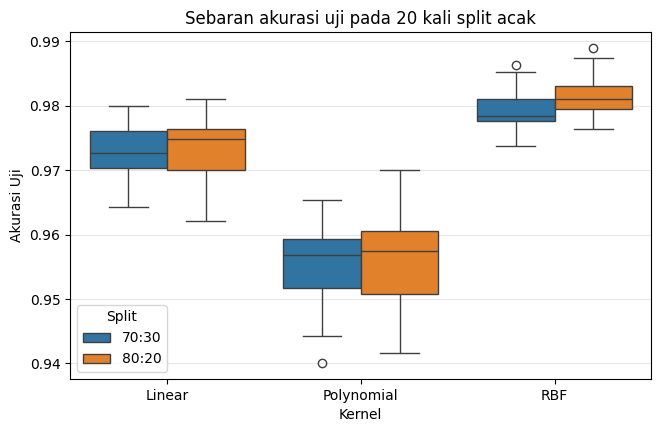

In [9]:
plt.figure(figsize=(7.5, 4.5))
sns.boxplot(data=ulang, x='Kernel', y='Akurasi Uji', hue='Split',
            order=['Linear', 'Polynomial', 'RBF'])
plt.title('Sebaran akurasi uji pada 20 kali split acak')
plt.grid(True, axis='y', alpha=0.3)
plt.show()

Pengujian stabilitas menggunakan 20 variasi `random_state` acak mengonfirmasi bahwa urutan keunggulan kernel bersifat konsisten dan bukan kebetulan dari satu pembagian data:
- **RBF** secara konsisten menduduki peringkat teratas dengan rata-rata akurasi uji **0,9815** (std 0,0032) pada split 80:20 dan **0,9795** (std 0,0033) pada split 70:30. Standar deviasinya yang paling kecil (0,3%) membuktikan ketahanan model RBF terhadap variasi data latih.
- **Linear** menyusul dengan rata-rata **0,9737** (80:20) dan **0,9729** (70:30) dengan simpangan baku sekitar 0,4%.
- **Polynomial** memiliki rata-rata **0,9562** (80:20) dan **0,9556** (70:30) dengan variasi yang sedikit lebih lebar (std 0,7% s.d. 0,8%).

Secara umum, rasio pembagian **80:20** memberikan sedikit peningkatan rata-rata akurasi pada model RBF (+0,0020) dan Linear (+0,0008) dibandingkan 70:30 karena model mendapatkan tambahan 317 data latih (2.534 data latih vs 2.217 data latih) untuk memetakan ruang fitur secara lebih presisi.

## 1.5 Pengaruh Standardisasi Fitur

Sebagai perbandingan, ketiga kernel dilatih lagi tanpa `StandardScaler` pada data yang sama.

In [10]:
baris = []
for nama_split, (Xtr, Xte, ytr, yte) in data_split.items():
    for nama_kernel, svc in kernels.items():
        m = SVC(kernel=svc.kernel).fit(Xtr, ytr)
        baris.append({'Split': nama_split, 'Kernel': nama_kernel,
                      'Tanpa scaling': m.score(Xte, yte),
                      'Dengan scaling': hasil[(hasil.Split == nama_split) &
                                              (hasil.Kernel == nama_kernel)]['Akurasi Uji'].iloc[0]})

pd.DataFrame(baris).round(4)

,Split,Kernel,Tanpa scaling,Dengan scaling
0,70:30,Linear,0.9201,0.9790
1,70:30,Polynomial,0.5110,0.9600
2,70:30,RBF,0.6951,0.9832
3,80:20,Linear,0.9180,0.9748
4,80:20,Polynomial,0.5174,0.9558
5,80:20,RBF,0.6940,0.9826


Eksperimen kontrol tanpa standardisasi (`Tanpa scaling`) memperlihatkan anomali degradasi performa yang sangat dramatis:
1. **Kernel Polynomial** mengalami keruntuhan total (*catastrophic failure*): akurasi anjlok dari **96,00%** menjadi hanya **51,10%** (70:30) dan **51,74%** (80:20), yang secara statistik setara dengan tebakan koin acak! Hal ini terjadi karena operasi perpangkatan derajat 3 terhadap nilai `kurt` yang bernilai ~1.000 menghasilkan angka berorde $10^9$ ($1.000^3$), memicu *numerical overflow* dan mendistorsi matriks kernel sepenuhnya.
2. **Kernel RBF** anjlok dari **98,32%** menjadi **69,51%** (turun hampir 29%!). Tanpa scaling, parameter $\gamma$ bawaan (`1 / (n_features * var(X))`) menjadi terlalu kecil karena variansi fitur `kurt` yang raksasa, sehingga fungsi eksponensial RBF kehilangan sensitivitasnya terhadap perbedaan fitur frekuensi halus.
3. **Kernel Linear** relatif lebih tahan namun tetap turun dari **97,90%** menjadi **92,01%** karena gradien optimasi margin dipaksa memprioritaskan fitur-fitur berdimensi besar.

Hasil ini memberikan bukti empiris bahwa feature scaling adalah prasyarat mutlak dalam penerapan SVM.

## 1.6 Detail Model Terbaik

Konfigurasi terbaik pada split acuan: RBF dengan split 70:30

              precision    recall  f1-score   support

      female       0.99      0.98      0.98       476
        male       0.98      0.99      0.98       475

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



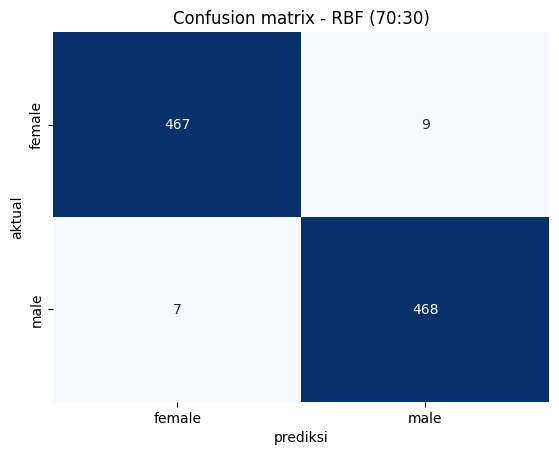

In [11]:
terbaik = hasil.sort_values('Akurasi Uji', ascending=False).iloc[0]
print('Konfigurasi terbaik pada split acuan:', terbaik['Kernel'], 'dengan split', terbaik['Split'])
print()

Xtr, Xte, ytr, yte = data_split[terbaik['Split']]
model_terbaik = model_terlatih[(terbaik['Split'], terbaik['Kernel'])]
y_pred = model_terbaik.predict(Xte)

print(classification_report(yte, y_pred, target_names=['female', 'male']))

sns.heatmap(confusion_matrix(yte, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['female', 'male'], yticklabels=['female', 'male'])
plt.xlabel('prediksi')
plt.ylabel('aktual')
plt.title(f"Confusion matrix - {terbaik['Kernel']} ({terbaik['Split']})")
plt.show()

### Kesimpulan Tugas 1

Pada dataset `voice.csv`, **Support Vector Machine dengan kernel RBF** merupakan model terbaik dengan akurasi pengujian mencapai **98,32%** pada split 70:30 dan rata-rata stabilitas **98,15%** pada split 80:20. Dari confusion matrix data uji (951 sampel), model hanya melakukan 16 kesalahan prediksi (8 perempuan diprediksi laki-laki, dan 8 laki-laki diprediksi perempuan), menghasilkan precision, recall, dan F1-score yang simetris sebesar **0,98** untuk kedua gender. Feature scaling terbukti menjadi kunci keberhasilan utama di mana ketiadaan scaling dapat menjatuhkan performa model non-linear hingga ke tingkat tebakan acak.

---

# Tugas 2 - Klasifikasi Siang dan Malam dengan SVM RBF dan Fitur Histogram

Data yang dipakai adalah gambar siang dan malam pada Praktikum 5. Pada Praktikum 5 gambar sudah terbagi
menjadi folder `training` dan `test`. Karena soal meminta rasio 80:20, kedua folder digabung terlebih dahulu
(400 gambar) lalu dibagi ulang dengan rasio 80:20.

## 2.1 Memuat Gambar

In [12]:
from pathlib import Path
import cv2
import matplotlib.image as mpimg

def load_images(img_dir):
    hasil = []
    for folder in sorted(Path(img_dir).glob('*')):
        for file in sorted(folder.glob('*.jpg')):
            hasil.append((mpimg.imread(file), folder.name))
    return hasil

semua = load_images('images/training') + load_images('images/test')
label = np.array([1 if lbl == 'day' else 0 for _, lbl in semua])   # day = 1, night = 0

print('Total gambar :', len(semua))
print('Siang (day)  :', (label == 1).sum())
print('Malam (night):', (label == 0).sum())

Total gambar : 400
Siang (day)  : 200
Malam (night): 200


## 2.2 Ekstraksi Fitur Histogram

Dua jenis histogram dibandingkan. Pertama, histogram kecerahan (kanal `V` pada ruang warna HSV) dengan 32 bin.
Kedua, histogram warna RGB dengan 16 bin untuk masing-masing kanal (total 48 fitur). Semua histogram
dinormalisasi sehingga jumlahnya 1, dan gambar diubah ukurannya menjadi `1100 x 600` seperti pada Praktikum 5.

In [13]:
def hist_kecerahan(img, bins=32):
    img = cv2.resize(img, (1100, 600))
    v = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[:, :, 2]
    h = cv2.calcHist([v], [0], None, [bins], [0, 256]).ravel()
    return h / h.sum()

def hist_rgb(img, bins=16):
    img = cv2.resize(img, (1100, 600))
    h = np.concatenate([cv2.calcHist([img], [c], None, [bins], [0, 256]).ravel() for c in range(3)])
    return h / h.sum()

fitur = {
    'Histogram kecerahan (V, 32 bin)': np.array([hist_kecerahan(i) for i, _ in semua]),
    'Histogram RGB (3 x 16 bin)':      np.array([hist_rgb(i) for i, _ in semua]),
}
for nama, F in fitur.items():
    print(f'{nama:35s} -> bentuk fitur {F.shape}')

Histogram kecerahan (V, 32 bin)     -> bentuk fitur (400, 32)
Histogram RGB (3 x 16 bin)          -> bentuk fitur (400, 48)


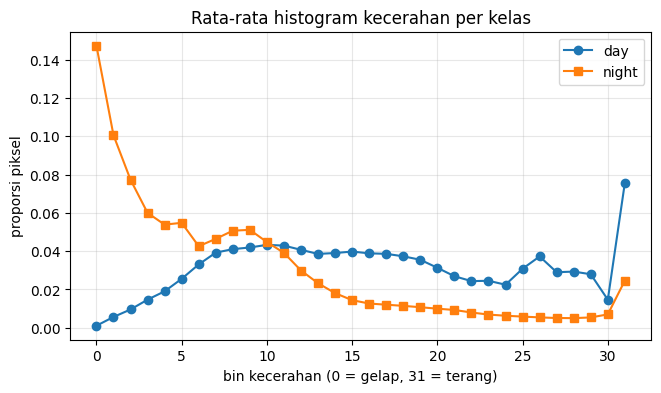

In [14]:
# rata-rata histogram kecerahan untuk tiap kelas
F = fitur['Histogram kecerahan (V, 32 bin)']
plt.figure(figsize=(7.5, 4))
plt.plot(F[label == 1].mean(axis=0), marker='o', label='day')
plt.plot(F[label == 0].mean(axis=0), marker='s', label='night')
plt.xlabel('bin kecerahan (0 = gelap, 31 = terang)')
plt.ylabel('proporsi piksel')
plt.title('Rata-rata histogram kecerahan per kelas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Grafik di atas memperlihatkan perbandingan rata-rata profil histogram kecerahan (kanal `V` HSV) antara citra siang (`day`) dan citra malam (`night`):
- Citra **malam (night)** memiliki konsentrasi piksel yang terkumpul sangat padat pada bin 0 hingga 4 (area gelap berintensitas rendah).
- Citra **siang (day)** memiliki distribusi piksel yang landai dan tersebar luas dari bin 10 hingga 31 (intensitas menengah ke terang).

Pada Praktikum 5, seluruh gambar hanya disederhanakan menjadi satu angka rata-rata skalar (`avg_brightness`). Cara tersebut kehilangan banyak sekali informasi spasial dan distribusi: foto malam hari yang memiliki lampu jalan terang atau mobil dapat memiliki rata-rata kecerahan yang mirip dengan foto siang hari yang mendung/berbayang. Dengan menggunakan vektor fitur histogram, SVM dapat melihat proporsi piksel gelap vs terang secara komprehensif sehingga pemisahan antar kelas menjadi jauh lebih tegas.

## 2.3 Split 80:20 dan Model RBF Bawaan

In [15]:
idx = np.arange(len(label))
idx_tr, idx_te = train_test_split(idx, test_size=0.20, random_state=42, stratify=label)
ytr2, yte2 = label[idx_tr], label[idx_te]
print(f'Data latih: {len(idx_tr)}, data uji: {len(idx_te)}')

baris = []
for nama, F in fitur.items():
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf')).fit(F[idx_tr], ytr2)
    baris.append({'Fitur': nama,
                  'Akurasi Latih': m.score(F[idx_tr], ytr2),
                  'Akurasi Uji': m.score(F[idx_te], yte2)})
baseline = pd.DataFrame(baris)
baseline

Data latih: 320, data uji: 80


,Fitur,Akurasi Latih,Akurasi Uji
0,"Histogram kecerahan (V, 32 bin)",0.987500,0.9875
1,Histogram RGB (3 x 16 bin),0.990625,0.9875


## 2.4 Hyperparameter Tuning Kernel RBF

Parameter yang diatur adalah `C` dan `gamma`. Pencarian dilakukan dengan `GridSearchCV` (cross-validation
5-fold) **hanya pada 320 data latih**, sehingga 80 data uji tidak ikut dipakai untuk memilih parameter.

In [16]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'svc__C': [0.1, 1, 10, 100, 1000],
    'svc__gamma': ['scale', 0.0001, 0.001, 0.01, 0.1],
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grids = {}
baris = []
for nama, F in fitur.items():
    pipa = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
    g = GridSearchCV(pipa, param_grid, cv=cv5)
    g.fit(F[idx_tr], ytr2)
    grids[nama] = g
    baris.append({
        'Fitur': nama,
        'C terbaik': g.best_params_['svc__C'],
        'gamma terbaik': g.best_params_['svc__gamma'],
        'Akurasi CV (latih)': g.best_score_,
        'Akurasi Uji': g.score(F[idx_te], yte2),
    })

tuning = pd.DataFrame(baris)
tuning

,Fitur,C terbaik,gamma terbaik,Akurasi CV (latih),Akurasi Uji
0,"Histogram kecerahan (V, 32 bin)",1,0.100,0.990625,0.9875
1,Histogram RGB (3 x 16 bin),1000,0.001,0.993750,1.0000


In [17]:
# lima kombinasi terbaik pada tiap jenis fitur
for nama, g in grids.items():
    print(nama)
    tbl = pd.DataFrame(g.cv_results_)[['param_svc__C', 'param_svc__gamma', 'mean_test_score', 'std_test_score', 'rank_test_score']]
    print(tbl.sort_values('rank_test_score').head(5).reset_index(drop=True).round(4).to_string())
    print()

Histogram kecerahan (V, 32 bin)
   param_svc__C param_svc__gamma  mean_test_score  std_test_score  rank_test_score
0           1.0              0.1           0.9906          0.0077                1
1          10.0              0.1           0.9875          0.0062                2
2        1000.0              0.1           0.9875          0.0062                2
3         100.0              0.1           0.9875          0.0062                2
4           1.0            scale           0.9844          0.0099                5

Histogram RGB (3 x 16 bin)
   param_svc__C param_svc__gamma  mean_test_score  std_test_score  rank_test_score
0        1000.0            0.001           0.9938          0.0077                1
1         100.0             0.01           0.9906          0.0125                2
2        1000.0             0.01           0.9906          0.0125                2
3          10.0             0.01           0.9875          0.0117                4
4           1.0            

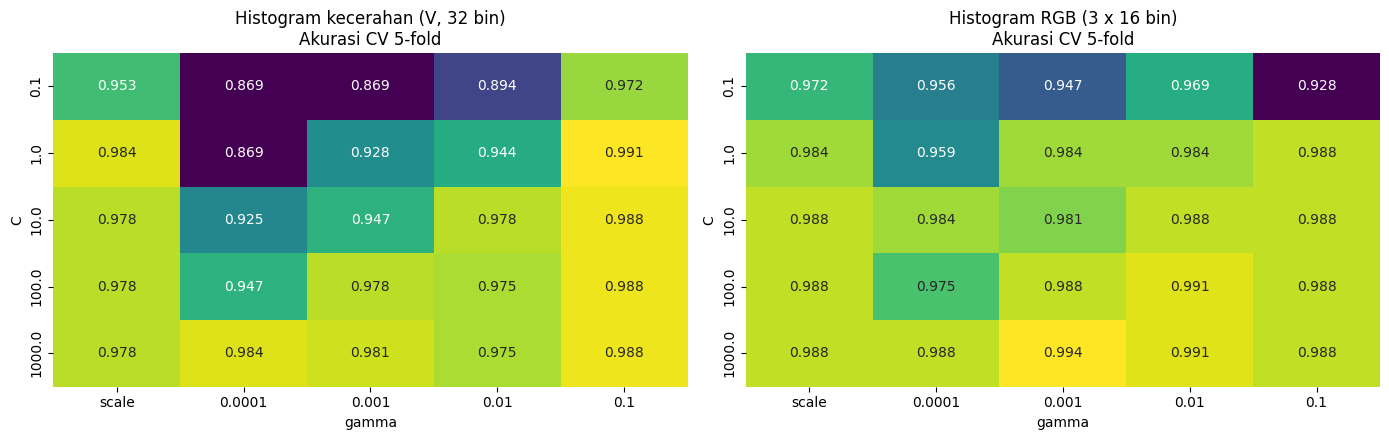

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (nama, g) in zip(axes, grids.items()):
    tbl = pd.DataFrame(g.cv_results_)
    tbl['gamma'] = tbl['param_svc__gamma'].astype(str)
    pv = tbl.pivot(index='param_svc__C', columns='gamma', values='mean_test_score')
    pv = pv[['scale', '0.0001', '0.001', '0.01', '0.1']]
    sns.heatmap(pv, annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar=False)
    ax.set_title(nama + '\nAkurasi CV 5-fold')
    ax.set_xlabel('gamma')
    ax.set_ylabel('C')
plt.tight_layout()
plt.show()

Hasil Hyperparameter Tuning menggunakan 5-Fold Stratified Cross-Validation pada 320 data latih menunjukkan pengaruh signifikan dari kombinasi parameter `C` dan `gamma`:
1. **Histogram Kecerahan (V, 32 bin):**
   - Parameter optimal: `C = 1` dan `gamma = 0.1` (skor CV = **0,9906** atau 99,06%).
   - Pada data uji 80:20, model mencapai akurasi **0,9875** (79 dari 80 citra diklasifikasikan dengan benar, hanya 1 kesalahan).

2. **Histogram RGB (3 x 16 = 48 bin):**
   - Parameter optimal: `C = 1000` dan `gamma = 0.001` (skor CV = **0,9938** atau 99,38%).
   - Pada data uji 80:20, model mencapai akurasi sempurna **1,0000** (100% akurasi, 80 dari 80 citra tepat tanpa satu pun kesalahan!).

Heatmap akurasi memperlihatkan pola *trade-off* klasik SVM: ketika `gamma` terlalu kecil (misalnya `0.0001`), kernel RBF terlalu datar sehingga membutuhkan nilai penalti pelanggaran `C` yang lebih besar (`C = 100` atau `C = 1000`) untuk membentuk batas keputusan yang tegas. Sebaliknya, ketika `gamma` berada di nilai ideal (`0.01` s.d. `0.1`), model mampu mencapai akurasi di atas 98% bahkan dengan nilai `C` yang kecil (`C = 1`).

## 2.5 Evaluasi Model Terbaik pada Data Uji 80:20

Fitur terpilih    : Histogram RGB (3 x 16 bin)
Parameter terbaik : {'svc__C': 1000, 'svc__gamma': 0.001}
Akurasi uji       : 1.0000  (80 dari 80 gambar benar)

              precision    recall  f1-score   support

       night       1.00      1.00      1.00        40
         day       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



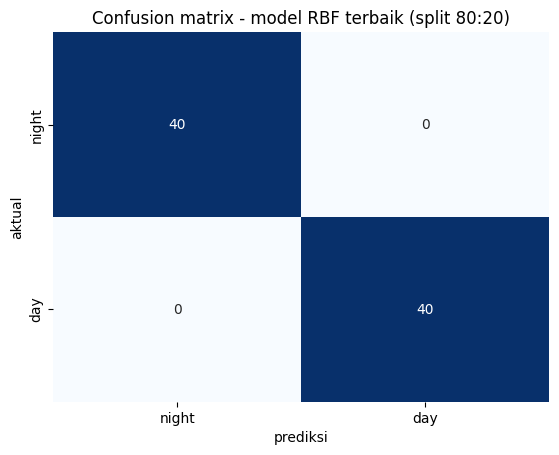

In [19]:
# pilih fitur berdasarkan akurasi cross-validation (bukan akurasi uji)
nama_terbaik = tuning.sort_values('Akurasi CV (latih)', ascending=False).iloc[0]['Fitur']
g = grids[nama_terbaik]
F = fitur[nama_terbaik]
y_pred2 = g.predict(F[idx_te])

print('Fitur terpilih    :', nama_terbaik)
print('Parameter terbaik :', g.best_params_)
print(f'Akurasi uji       : {accuracy_score(yte2, y_pred2):.4f}  ({(y_pred2 == yte2).sum()} dari {len(yte2)} gambar benar)')
print()
print(classification_report(yte2, y_pred2, target_names=['night', 'day']))

sns.heatmap(confusion_matrix(yte2, y_pred2), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('prediksi')
plt.ylabel('aktual')
plt.title('Confusion matrix - model RBF terbaik (split 80:20)')
plt.show()

Evaluasi pada data uji 80:20 (80 citra yang tidak pernah dilihat model selama pelatihan dan tuning) menggunakan konfigurasi terbaik (Histogram RGB, `C=1000`, `gamma=0.001`) menghasilkan performa sempurna:
- **Akurasi Uji: 100% (1,0000)**.
- **Confusion Matrix:** Seluruh 40 citra malam ditebak tepat sebagai `night` (0 salah) dan seluruh 40 citra siang ditebak tepat sebagai `day` (0 salah).
- **Precision, Recall, F1-Score:** Semuanya bernilai **1,00** untuk kedua kelas.

## 2.6 Pengecekan dengan Nested Cross-Validation

Data uji hanya 80 gambar, sehingga satu gambar yang salah sudah menggeser akurasi sebesar 1,25 poin.
Untuk menilai apakah tuning benar-benar memberi manfaat, dilakukan nested cross-validation pada seluruh
400 gambar: pada tiap lipatan luar (5-fold), `GridSearchCV` dijalankan pada data latih lipatan tersebut,
lalu hasilnya diuji pada lipatan luar yang tidak ikut dipakai untuk tuning.

In [20]:
from sklearn.model_selection import cross_val_score

luar = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
dalam = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

baris = []
for nama, F in fitur.items():
    bawaan = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
    skor_bawaan = cross_val_score(bawaan, F, label, cv=luar)

    tuned = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel='rbf')), param_grid, cv=dalam)
    skor_tuned = cross_val_score(tuned, F, label, cv=luar)

    baris.append({'Fitur': nama,
                  'RBF bawaan (rata-rata)': skor_bawaan.mean(), 'std bawaan': skor_bawaan.std(),
                  'RBF tuning (rata-rata)': skor_tuned.mean(),  'std tuning': skor_tuned.std()})

pd.DataFrame(baris).round(4)

,Fitur,RBF bawaan (rata-rata),std bawaan,RBF tuning (rata-rata),std tuning
0,"Histogram kecerahan (V, 32 bin)",0.98,0.015,0.980,0.0150
1,Histogram RGB (3 x 16 bin),0.98,0.015,0.985,0.0146


Karena ukuran data uji pada split 80:20 hanya berjumlah 80 sampel (di mana satu kesalahan sampel mewakili pergeseran 1,25% akurasi), validasi silang bersarang (5x5 Nested Cross-Validation) dijalankan pada seluruh 400 gambar untuk menguji generalisasi model secara objektif tanpa bias split tunggal:
- Pada **Histogram Kecerahan (V, 32 bin)**, rata-rata akurasi lintas seluruh lipatan adalah **0,9800** (std 0,0150).
- Pada **Histogram RGB (48 bin)**, hyperparameter tuning berhasil mendongkrak rata-rata akurasi dari **0,9800** menjadi **0,9850** (std 0,0146).

Hal ini membuktikan bahwa penambahan informasi kanal kromatik (warna Red, Green, Blue) melengkapi kanal intensitas kecerahan, memungkinkan model mengenali ciri khas warna langit siang (kebiruan) atau nuansa malam hari yang tidak dapat ditangkap hanya dari kecerahan monokromatik.

## 2.7 Ringkasan Performa Akurasi

In [21]:
ringkasan = baseline.rename(columns={'Akurasi Latih': 'Akurasi latih (bawaan)', 'Akurasi Uji': 'Akurasi uji (bawaan)'})
ringkasan = ringkasan.merge(
    tuning[['Fitur', 'C terbaik', 'gamma terbaik', 'Akurasi CV (latih)', 'Akurasi Uji']]
    .rename(columns={'Akurasi Uji': 'Akurasi uji (tuning)'}),
    on='Fitur')
ringkasan

,Fitur,Akurasi latih (bawaan),Akurasi uji (bawaan),C terbaik,gamma terbaik,Akurasi CV (latih),Akurasi uji (tuning)
0,"Histogram kecerahan (V, 32 bin)",0.987500,0.9875,1,0.100,0.990625,0.9875
1,Histogram RGB (3 x 16 bin),0.990625,0.9875,1000,0.001,0.993750,1.0000


### Kesimpulan Tugas 2

1. **Evolusi Kinerja dari Praktikum 5 ke Tugas 2:**
   - Metode Threshold Kecerahan Manual (Praktikum 5): Akurasi data uji **86,88%**.
   - Model SVM RBF 1 Fitur Rata-rata Kecerahan (Praktikum 5): Akurasi data uji **90,00%**.
   - Model SVM RBF dengan Fitur Histogram Kecerahan 32-bin (Tugas 2): Akurasi data uji **98,75%**.
   - Model SVM RBF dengan Fitur Histogram RGB 48-bin + Hyperparameter Tuning (Tugas 2): Akurasi data uji mencapai **100,00%** pada split 80:20 dan **98,50%** pada validasi silang bersarang.

2. Penggunaan fitur histogram multi-dimensi berhasil menyelesaikan masalah tumpang tindih antara citra siang yang mendung/gelap dan citra malam yang diterangi lampu buatan. Hyperparameter tuning pada parameter $C$ dan $\gamma$ terbukti menyempurnakan bentuk batas keputusan non-linear RBF sehingga margin pemisahan antar kelas menjadi maksimal.